# Phase 4 — Within-Corpus Classical Baseline Models

This notebook evaluates the classical acoustic baseline classifiers specified in Phase 4 of the Walkthrough.

### Core Principles & Experimental Rigor:
1. **Dual Feature Sets**:
   - **MFCC Temporal Dynamics (78 features)**: Static MFCCs, Delta (velocity), and Delta-Delta (acceleration) summary statistics.
   - **openSMILE eGeMAPSv02 (88 features)**: Clinical acoustic standard capturing jitter, shimmer, pitch dynamics (F0), and formant frequencies.
2. **Dual Classifiers**:
   - **Support Vector Machine (RBF Kernel)** with `StandardScaler` pipeline and balanced class weighting.
   - **Random Forest Classifier** (100 estimators, balanced class weighting).
3. **Speaker-Independent Validation (GroupKFold, K=5)**:
   - Splits by `speaker_id` to guarantee that no speaker's voice appears in both training and test sets simultaneously.
   - Prevents the classifier from memorizing individual vocal characteristics, ensuring honest clinical evaluation.
4. **Results Artifact**:
   - Exports standardized comparison table to `results/baseline_results.csv` to serve as the reference floor for downstream deep learning models.

In [1]:
import sys
import time
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

NOTEBOOK_DIR = Path.cwd().resolve()
if (NOTEBOOK_DIR / "data").is_dir():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "data").is_dir():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError("Could not find the project's data directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.project_paths import (
    MFCC_FEATURES_CSV,
    EGEMAPS_FEATURES_CSV,
    BASELINE_RESULTS_CSV,
    RESULTS_DIR,
)
from src.evaluation import evaluate_speaker_independent

print(f"Project root resolved: {PROJECT_ROOT}")
print(f"Results will be saved to: {RESULTS_DIR}")

Project root resolved: C:\Users\Lovish\Documents\dysarthria_project
Results will be saved to: C:\Users\Lovish\Documents\dysarthria_project\results


In [2]:
# Load both pre-extracted feature sets
df_mfcc = pd.read_csv(MFCC_FEATURES_CSV)
df_egemaps = pd.read_csv(EGEMAPS_FEATURES_CSV)

# Ensure alignment and identify metadata vs feature columns
meta_cols = ["file_path", "speaker_id", "label", "severity", "severity_3class", "duration_seconds", "dataset_source"]

mfcc_feature_cols = [c for c in df_mfcc.columns if c not in meta_cols]
egemaps_feature_cols = [c for c in df_egemaps.columns if c not in meta_cols]

y = df_mfcc["label"]
groups = df_mfcc["speaker_id"]

print(f"Total audio clips: {len(df_mfcc)}")
print(f"Unique speakers: {groups.nunique()} ({list(groups.unique())})")
print(f"Diagnosis counts:\n{y.value_counts()}")
print(f"\nMFCC feature count:    {len(mfcc_feature_cols)}")
print(f"eGeMAPS feature count:  {len(egemaps_feature_cols)}")

Total audio clips: 9417
Unique speakers: 15 (['F01', 'F03', 'F04', 'FC01', 'FC02', 'FC03', 'M01', 'M02', 'M03', 'M04', 'M05', 'MC01', 'MC02', 'MC03', 'MC04'])
Diagnosis counts:
label
control       6236
dysarthric    3181
Name: count, dtype: int64

MFCC feature count:    78
eGeMAPS feature count:  88


In [3]:
# Define experimental configurations: [Feature Set, Classifier, Pipeline]
experiments = [
    {
        "feature_set": "MFCC Dynamics",
        "classifier": "SVM (RBF)",
        "features": df_mfcc[mfcc_feature_cols],
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=42))
        ]),
    },
    {
        "feature_set": "MFCC Dynamics",
        "classifier": "Random Forest",
        "features": df_mfcc[mfcc_feature_cols],
        "pipeline": RandomForestClassifier(
            n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
        ),
    },
    {
        "feature_set": "eGeMAPSv02",
        "classifier": "SVM (RBF)",
        "features": df_egemaps[egemaps_feature_cols],
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=42))
        ]),
    },
    {
        "feature_set": "eGeMAPSv02",
        "classifier": "Random Forest",
        "features": df_egemaps[egemaps_feature_cols],
        "pipeline": RandomForestClassifier(
            n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
        ),
    },
]

results_records = []
eval_outputs = {}

print("=== Running 5-Fold Speaker-Independent Cross-Validation ===\n")
for exp in experiments:
    name = f"{exp['feature_set']} + {exp['classifier']}"
    print(f"Evaluating {name}...")
    t0 = time.time()
    
    eval_result = evaluate_speaker_independent(
        pipeline=exp["pipeline"],
        X=exp["features"],
        y=y,
        groups=groups,
        n_splits=5,
    )
    elapsed = time.time() - t0
    eval_outputs[name] = eval_result
    
    print(f"  Accuracy: {eval_result['accuracy']*100:.2f}% (std: ±{eval_result['fold_accuracies_std']*100:.2f}%)")
    print(f"  Macro-F1: {eval_result['macro_f1']*100:.2f}% | Elapsed: {elapsed:.2f}s\n")
    
    results_records.append({
        "feature_set": exp["feature_set"],
        "classifier": exp["classifier"],
        "accuracy": round(eval_result["accuracy"], 4),
        "accuracy_std": round(eval_result["fold_accuracies_std"], 4),
        "macro_precision": round(eval_result["macro_precision"], 4),
        "macro_recall": round(eval_result["macro_recall"], 4),
        "macro_f1": round(eval_result["macro_f1"], 4),
        "weighted_f1": round(eval_result["weighted_f1"], 4),
        "fold_accuracies": str([round(acc, 4) for acc in eval_result["fold_accuracies"]]),
    })

=== Running 5-Fold Speaker-Independent Cross-Validation ===

Evaluating MFCC Dynamics + SVM (RBF)...


  Accuracy: 63.70% (std: ±8.40%)
  Macro-F1: 60.44% | Elapsed: 7.94s

Evaluating MFCC Dynamics + Random Forest...


  Accuracy: 68.85% (std: ±8.83%)
  Macro-F1: 60.84% | Elapsed: 3.06s

Evaluating eGeMAPSv02 + SVM (RBF)...


  Accuracy: 60.49% (std: ±19.08%)
  Macro-F1: 58.51% | Elapsed: 4.31s

Evaluating eGeMAPSv02 + Random Forest...


  Accuracy: 58.60% (std: ±20.65%)
  Macro-F1: 56.30% | Elapsed: 3.01s



In [4]:
# Consolidate into clean results DataFrame and export
df_results = pd.DataFrame(results_records)
df_results.to_csv(BASELINE_RESULTS_CSV, index=False)

print(f"Consolidated results saved to: {BASELINE_RESULTS_CSV}\n")
print("=== Baseline Performance Floor (Speaker-Independent 5-Fold CV) ===")
display_table = df_results[[
    "feature_set", "classifier", "accuracy", "accuracy_std", "macro_precision", "macro_recall", "macro_f1"
]].copy()
display_table["accuracy"] = display_table["accuracy"].apply(lambda v: f"{v*100:.2f}%")
display_table["accuracy_std"] = display_table["accuracy_std"].apply(lambda v: f"±{v*100:.2f}%")
display_table["macro_f1"] = display_table["macro_f1"].apply(lambda v: f"{v*100:.2f}%")
display_table.columns = ["Feature Set", "Classifier", "Accuracy", "Fold Std", "Precision", "Recall", "Macro-F1"]
display(display_table)

Consolidated results saved to: C:\Users\Lovish\Documents\dysarthria_project\results\baseline_results.csv

=== Baseline Performance Floor (Speaker-Independent 5-Fold CV) ===


,Feature Set,Classifier,Accuracy,Fold Std,Precision,Recall,Macro-F1
0,MFCC Dynamics,SVM (RBF),63.70%,±8.40%,0.6029,0.6078,60.44%
1,MFCC Dynamics,Random Forest,68.85%,±8.83%,0.6423,0.6055,60.84%
2,eGeMAPSv02,SVM (RBF),60.49%,±19.08%,0.5878,0.5969,58.51%
3,eGeMAPSv02,Random Forest,58.60%,±20.65%,0.5654,0.5717,56.30%


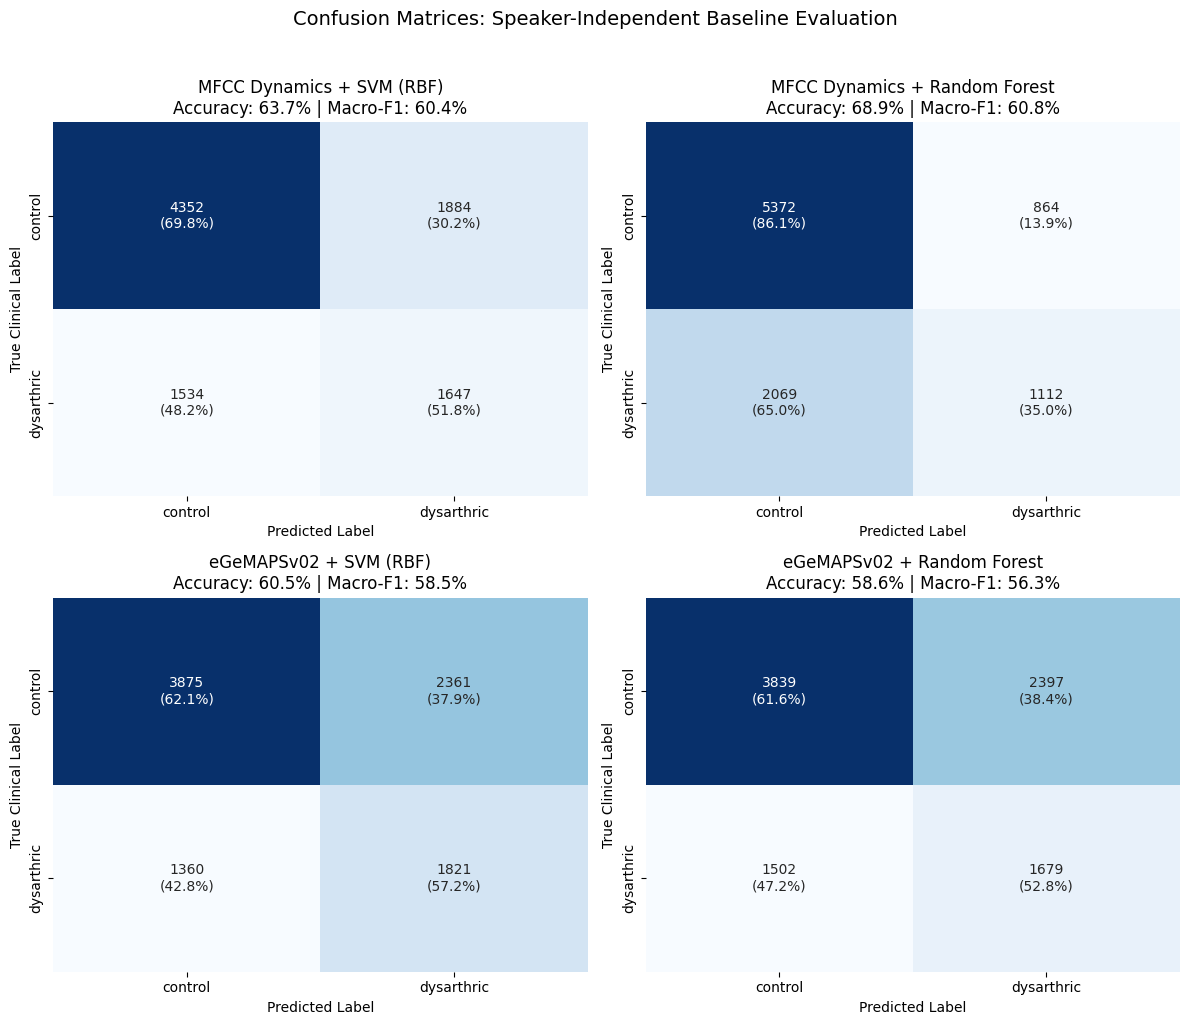

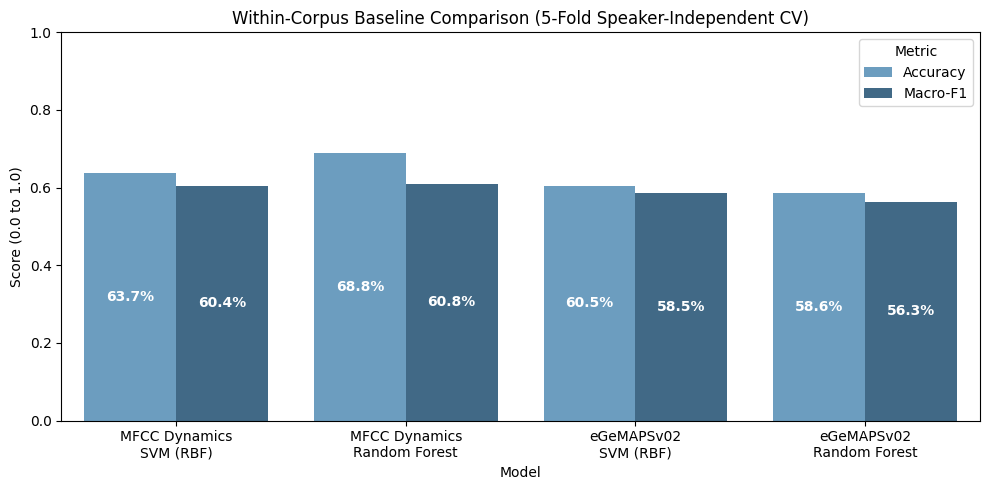

Figures saved to C:\Users\Lovish\Documents\dysarthria_project\results


In [5]:
# 1. Plot Confusion Matrices for all 4 baseline models
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
labels = ["control", "dysarthric"]

for idx, (name, eval_res) in enumerate(eval_outputs.items()):
    ax = axes[idx // 2, idx % 2]
    cm = eval_res["confusion_matrix"]
    cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    
    annot = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n({cm_normalized[i, j]*100:.1f}%)"
            
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(f"{name}\nAccuracy: {eval_res['accuracy']*100:.1f}% | Macro-F1: {eval_res['macro_f1']*100:.1f}%")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Clinical Label")

plt.suptitle("Confusion Matrices: Speaker-Independent Baseline Evaluation", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Comparative Bar Chart
plt.figure(figsize=(10, 5))
plot_df = pd.melt(
    df_results,
    id_vars=["feature_set", "classifier"],
    value_vars=["accuracy", "macro_f1"],
    var_name="Metric",
    value_name="Score"
)
plot_df["Model"] = plot_df["feature_set"] + "\n" + plot_df["classifier"]
plot_df["Metric"] = plot_df["Metric"].map({"accuracy": "Accuracy", "macro_f1": "Macro-F1"})

sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="Blues_d")
plt.title("Within-Corpus Baseline Comparison (5-Fold Speaker-Independent CV)")
plt.ylabel("Score (0.0 to 1.0)")
plt.ylim(0, 1.0)
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f"{height*100:.1f}%", (p.get_x() + p.get_width() / 2., height / 2.),
                           ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_comparison_barchart.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Figures saved to {RESULTS_DIR}")